# Results: Edge, 2B, 9B and 27B

It reads the saved runs in `results/`: Edge and 2B from `run_edge_2b_locally.ipynb`, 9B and 27B from `run_9b_27b_on_pod.ipynb`.
No model or pod is started here. Figures are saved to `figures/`.

## 1. Load and score the runs

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from src.evaluate import accuracy, compare, load_results, score, twin_pairs
from src.questions import RUNS, load_questions

MODELS = {"edge": "GLiClass v4 Edge", "2b": "GLiClass v4 2B", "9b": "GLiClass v4 9B", "27b": "GLiClass v4 27B"}  # result-file prefix: label in tables and charts
RUN_LABELS = {"label_graph": "Labels + graph", "label_nograph": "Labels, no graph",
              "description_graph": "Label descriptions + graph", "label_noedges": "Labels + graph, no edges",
              "label_norules": "Labels + graph, no rules", "label_nograph_norules": "Labels, no graph, no rules",
              "description_nograph_norules": "Label descriptions, no graph, no rules"}
QUESTION_TYPES = ["lookup", "graph", "computation", "semantic"]


def percent(value):
    """Format a fraction as a percentage with one decimal, dropping a trailing .0: 82.5%, 100%."""
    return f"{value * 100:.1f}".removesuffix(".0") + "%"

questions = load_questions("questions.json")
scored = {}
for model in MODELS:
    for run in RUNS:
        path = Path(f"results/{model}_{run}.json")
        if path.exists():
            settings, answers = load_results(path)
            scored[(model, run)] = score(answers, questions, settings["include_graph"])
        else:
            print(f"Missing: {path}")

## 2. Correct answers per model and run

Each cell is correct / questions. The question-type columns include the twins; the `twins` column counts them separately.

In [3]:
RUN_NOTES = {
    "label_graph": "Input: graph excerpt + rules + question. Answer options: labels (e.g. SOME_ADMISSIONS); label descriptions never shown.",
    "label_nograph": "Input: rules + question, graph removed. Answer options: labels. Correct = INSUFFICIENT_INFORMATION.",
    "description_graph": "Input: graph excerpt + rules + question. Answer options: label descriptions instead of labels.",
    "label_noedges": "Input: graph excerpt without its relationship lines + rules + question. Answer options: labels. Correct = gold.",
    "label_norules": "Input: graph excerpt + question, rules removed. Answer options: labels. Correct = gold.",
    "label_nograph_norules": "Input: question only, empty text. Answer options: labels. Correct = INSUFFICIENT_INFORMATION.",
    "description_nograph_norules": "Input: question only, empty text. Answer options: label descriptions. Correct = INSUFFICIENT_INFORMATION.",
}


def correct_counts(table):
    """Return correct/total per question type, for the twins and for all questions."""
    by_type = accuracy(table, by="question_type").set_index("question_type")
    counts = {kind: f"{by_type.loc[kind, 'correct']}/{by_type.loc[kind, 'total']}"
              for kind in QUESTION_TYPES if kind in by_type.index}
    twins = table[table["twin"]]
    counts["twins"] = f"{int(twins['correct'].sum())}/{len(twins)}"
    counts["all"] = f"{int(table['correct'].sum())}/{len(table)}"
    return counts


summary = pd.DataFrame({(MODELS[model], run): correct_counts(table) for (model, run), table in scored.items()}).T
summary.index.names = ["model", "run"]
summary["comment"] = summary.index.get_level_values("run").map(RUN_NOTES)
with pd.option_context("display.max_colwidth", None):
    display(summary)

lookup graph computation  \
model            run                                                    
GLiClass v4 Edge label_graph                    2/5  3/13        9/16   
                 label_nograph                  5/5  5/13        6/16   
                 description_graph              4/5  4/13        6/16   
                 label_noedges                  2/5  3/13        8/16   
                 label_norules                  2/5  3/13        7/16   
                 label_nograph_norules          1/5  3/13        0/16   
                 description_nograph_norules    3/5  5/13        8/16   
GLiClass v4 2B   label_graph                    3/5  4/13        6/16   
                 label_nograph                  5/5  5/13       10/16   
                 description_graph              4/5  4/13       11/16   
                 label_noedges                  3/5  6/13        6/16   
                 label_norules                  4/5  4/13        7/16   
                 label_nograph_norules          1/5  5/13        3/16   
                 description_nograph_norules    3/5  4/13        9/16   
GLiClass v4 9B   label_graph                    5/5  6/13       11/16   
                 label_nograph                  3/5  0/13        5/16   
                 description_graph              5/5  8/13       12/16   
                 label_noedges                  5/5  4/13       12/16   
                 label_norules                  5/5  6/13       11/16   
                 label_nograph_norules          0/5  0/13        0/16   
                 description_nograph_norules    1/5  0/13        0/16   
GLiClass v4 27B  label_graph                    5/5  9/13       10/16   
                 label_nograph                  2/5  1/13        4/16   
                 description_graph              5/5  9/13       12/16   
                 label_noedges                  5/5  7/13       11/16   
                 label_norules                  5/5  7/13        9/16   
                 label_nograph_norules          0/5  0/13        0/16   
                 description_nograph_norules    0/5  3/13        1/16   

                                             semantic twins    all  \
model            run                                                 
GLiClass v4 Edge label_graph                     8/14  2/10  22/48   
                 label_nograph                   4/14  4/10  20/48   
                 description_graph               5/14  4/10  19/48   
                 label_noedges                   9/14  1/10  22/48   
                 label_norules                   9/14  1/10  21/48   
                 label_nograph_norules           4/14  0/10   8/48   
                 description_nograph_norules    11/14  5/10  27/48   
GLiClass v4 2B   label_graph                    11/14  2/10  24/48   
                 label_nograph                   9/14  4/10  29/48   
                 description_graph              12/14  3/10  31/48   
                 label_noedges                  10/14  2/10  25/48   
                 label_norules                  11/14  3/10  26/48   
                 label_nograph_norules          10/14  2/10  19/48   
                 description_nograph_norules    11/14  4/10  27/48   
GLiClass v4 9B   label_graph                    14/14  6/10  36/48   
                 label_nograph                   0/14  2/10   8/48   
                 description_graph              13/14  7/10  38/48   
                 label_noedges                  14/14  6/10  35/48   
                 label_norules                  14/14  6/10  36/48   
                 label_nograph_norules           0/14  0/10   0/48   
                 description_nograph_norules     0/14  0/10   1/48   
GLiClass v4 27B  label_graph                    14/14  7/10  38/48   
                 label_nograph                   0/14  2/10   7/48   
                 description_graph              14/14  7/10  40/48   
                 label_noedges    

## 3. Accuracy tables

The same numbers the charts below plot.

In [4]:
RUN_COMMENTS = {
    "label_graph": "The main test: can the model decide from the graph? Input: graph excerpt + rules + question. "
                "Answer options: labels, such as SOME_ADMISSIONS.",
    "label_nograph": "A control. Input: rules + question, without the graph. Answer options: labels. "
                  "The correct answer is always INSUFFICIENT_INFORMATION; a model that picks a substantive answer "
                  "is answering from the wording or the labels, not the graph.",
    "description_graph": "How much the label wording matters. Input: graph excerpt + rules + question. "
                  "Answer options: label descriptions instead of labels.",
    "label_noedges": "Whether the edges are needed. Input: the graph excerpt without its relationship lines + rules + question. "
                  "Answer options: labels. Scored against the same gold answers; unchanged scores mean the edges were not "
                  "necessary (record IDs on the nodes offer another route), not that they went unused.",
    "label_norules": "Whether the rules are needed. Input: graph excerpt + question, without the rules. Answer options: labels. "
                  "Scored against the same gold answers. For Q06, Q09, Q11-Q14 and Q26-Q30 the gold answer depends on "
                  "a rule, so lower scores there are expected.",
    "label_nograph_norules": "The bare control. Input: the question only, with empty text. Answer options: labels. "
                          "The correct answer is always INSUFFICIENT_INFORMATION; a model that picks a substantive answer "
                          "is answering from the wording, the labels or its own memory.",
    "description_nograph_norules": "Label wording without evidence. Input: the question only, with empty text. "
                            "Answer options: label descriptions. The correct answer is always INSUFFICIENT_INFORMATION; "
                            "it differs from Labels, no graph, no rules only in the label wording.",
}
TYPE_COMMENTS = {
    "lookup": "Read one recorded value off a node or its direct link, such as a dose amount, a unit, "
              "or whether a vaccine was recorded as given.",
    "graph": "Follow and compare linked records, one to three hops: does an administered dose match its prescription, "
             "do two admissions carry the same diagnoses (Q48 changes only the edges), does a medication event point "
             "to another admission's order, which lab results belong to a stay but are linked only to the patient.",
    "computation": "Calculate from recorded values: date and time order, 30-day readmission and mortality windows, "
                   "time tolerances, total dose against the prescribed dose, lab values against a reference range "
                   "or a threshold, and a lab trend.",
    "semantic": "Requires reading and interpreting the text in the nodes (what diagnosis and drug names mean, and which "
                "lab test a diagnosis refers to), not following the graph's structure. A Cypher query alone can't "
                "answer these without an outside mapping.",
}


def with_comments(table, comments):
    """Style a copy of table with percentages and a wrapped comment column; table itself feeds the charts unchanged."""
    commented = table.assign(comment=table.index.map(comments))
    return (commented.style.format(percent, subset=list(table.columns))
            .set_properties(subset=["comment"], **{"white-space": "normal", "width": "450px", "text-align": "left"}))


models_present = [label for model, label in MODELS.items() if any(key[0] == model for key in scored)]

overall = pd.DataFrame(
    [{"model": MODELS[model], "run": RUN_LABELS[run], "accuracy": accuracy(table).loc[0, "accuracy"]}
     for (model, run), table in scored.items()]
).pivot(index="run", columns="model", values="accuracy")
overall = overall.reindex(index=[RUN_LABELS[run] for run in RUNS], columns=models_present)

by_type = pd.DataFrame({
    MODELS[model]: accuracy(table, by="question_type").set_index("question_type")["accuracy"]
    for (model, run), table in scored.items() if run == "label_graph"
}).reindex(index=QUESTION_TYPES, columns=models_present)

display(with_comments(overall, {RUN_LABELS[run]: comment for run, comment in RUN_COMMENTS.items()}))
display(with_comments(by_type, TYPE_COMMENTS))

model,GLiClass v4 Edge,GLiClass v4 2B,GLiClass v4 9B,GLiClass v4 27B,comment
run,,,,,
Labels + graph,45.8%,50%,75%,79.2%,"The main test: can the model decide from the graph? Input: graph excerpt + rules + question. Answer options: labels, such as SOME_ADMISSIONS."
"Labels, no graph",41.7%,60.4%,16.7%,14.6%,"A control. Input: rules + question, without the graph. Answer options: labels. The correct answer is always INSUFFICIENT_INFORMATION; a model that picks a substantive answer is answering from the wording or the labels, not the graph."
Label descriptions + graph,39.6%,64.6%,79.2%,83.3%,How much the label wording matters. Input: graph excerpt + rules + question. Answer options: label descriptions instead of labels.
"Labels + graph, no edges",45.8%,52.1%,72.9%,77.1%,"Whether the edges are needed. Input: the graph excerpt without its relationship lines + rules + question. Answer options: labels. Scored against the same gold answers; unchanged scores mean the edges were not necessary (record IDs on the nodes offer another route), not that they went unused."
"Labels + graph, no rules",43.8%,54.2%,75%,72.9%,"Whether the rules are needed. Input: graph excerpt + question, without the rules. Answer options: labels. Scored against the same gold answers. For Q06, Q09, Q11-Q14 and Q26-Q30 the gold answer depends on a rule, so lower scores there are expected."
"Labels, no graph, no rules",16.7%,39.6%,0%,0%,"The bare control. Input: the question only, with empty text. Answer options: labels. The correct answer is always INSUFFICIENT_INFORMATION; a model that picks a substantive answer is answering from the wording, the labels or its own memory."
"Label descriptions, no graph, no rules",56.2%,56.2%,2.1%,12.5%,"Label wording without evidence. Input: the question only, with empty text. Answer options: label descriptions. The correct answer is always INSUFFICIENT_INFORMATION; it differs from Labels, no graph, no rules only in the label wording."


,GLiClass v4 Edge,GLiClass v4 2B,GLiClass v4 9B,GLiClass v4 27B,comment
question_type,,,,,
lookup,40%,60%,100%,100%,"Read one recorded value off a node or its direct link, such as a dose amount, a unit, or whether a vaccine was recorded as given."
graph,23.1%,30.8%,46.2%,69.2%,"Follow and compare linked records, one to three hops: does an administered dose match its prescription, do two admissions carry the same diagnoses (Q48 changes only the edges), does a medication event point to another admission's order, which lab results belong to a stay but are linked only to the patient."
computation,56.2%,37.5%,68.8%,62.5%,"Calculate from recorded values: date and time order, 30-day readmission and mortality windows, time tolerances, total dose against the prescribed dose, lab values against a reference range or a threshold, and a lab trend."
semantic,57.1%,78.6%,100%,100%,"Requires reading and interpreting the text in the nodes (what diagnosis and drug names mean, and which lab test a diagnosis refers to), not following the graph's structure. A Cypher query alone can't answer these without an outside mapping."


## 4. Charts

One color per model, the same in every chart. Values sit on the columns; the tables above hold the same numbers.

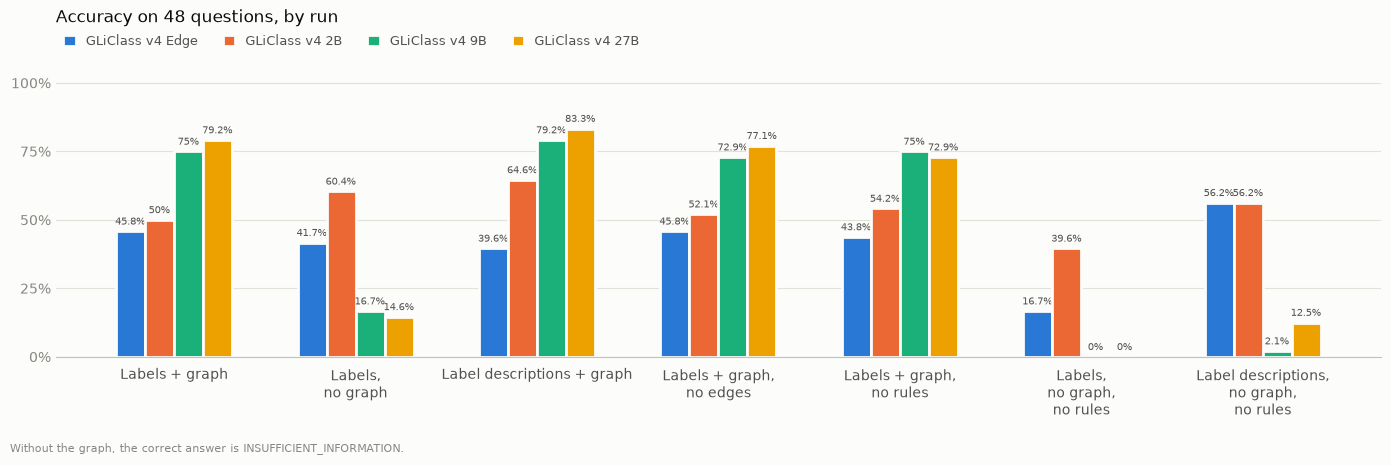

In [5]:
SERIES_COLORS = {"GLiClass v4 Edge": "#2a78d6", "GLiClass v4 2B": "#eb6834", "GLiClass v4 9B": "#1baf7a",
                 "GLiClass v4 27B": "#eda100"}  # validated categorical slots 1-4, in model-size order
SURFACE, TEXT, TEXT_SECONDARY, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BAR_WIDTH = 0.16


def grouped_columns(table, title, note=None, width=9):
    """Plot table (rows: groups on the x axis; columns: models) as grouped columns with values on the caps."""
    fig, ax = plt.subplots(figsize=(width, 4.4), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    groups = range(len(table.index))
    for i, model in enumerate(table.columns):
        offset = (i - (len(table.columns) - 1) / 2) * BAR_WIDTH
        bars = ax.bar([g + offset for g in groups], table[model], width=BAR_WIDTH, label=model,
                      color=SERIES_COLORS[model], edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.bar_label(bars, labels=[percent(value) for value in table[model]], padding=3,
                     fontsize=7.5, color=TEXT_SECONDARY)
    ax.set_xticks(list(groups), table.index)
    ax.set_ylim(0, 1.1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.spines["bottom"].set_zorder(4)  # keep the baseline above the gaps between columns
    ax.tick_params(axis="x", colors=TEXT_SECONDARY, length=0, pad=8)
    ax.tick_params(axis="y", colors=MUTED, length=0)
    ax.set_title(title, loc="left", color=TEXT, fontsize=12, pad=24)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=len(table.columns), frameon=False,
              labelcolor=TEXT_SECONDARY, fontsize=9, handlelength=1, handleheight=1, borderaxespad=0.2)
    if note:
        fig.text(0.01, -0.02, note, color=MUTED, fontsize=8, ha="left", va="top")
    fig.tight_layout()
    return fig


Path("figures").mkdir(exist_ok=True)
figure = grouped_columns(overall.rename(index=lambda label: label.replace(", ", ",\n")),  # two-line run labels
                         f"Accuracy on {len(questions)} questions, by run",
                         note="Without the graph, the correct answer is INSUFFICIENT_INFORMATION.", width=14)
figure.savefig("figures/accuracy_by_run.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()

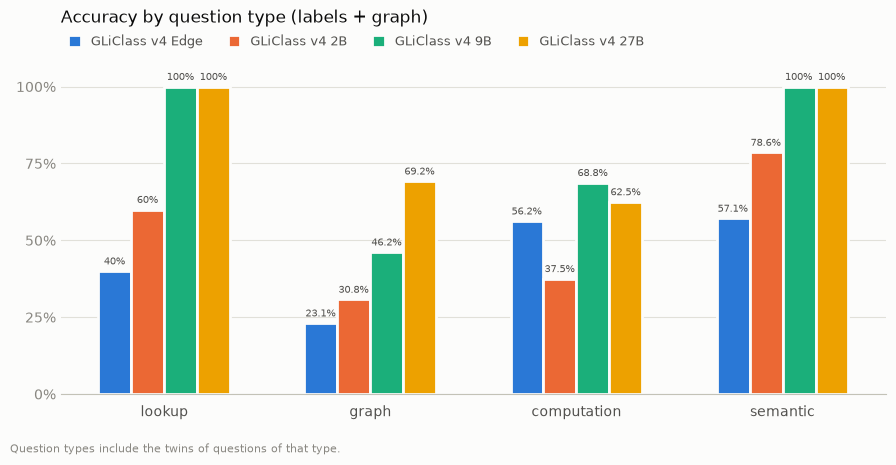

In [6]:
figure = grouped_columns(by_type, "Accuracy by question type (labels + graph)",
                         note="Question types include the twins of questions of that type.")
figure.savefig("figures/accuracy_by_question_type.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()

## 5. Per question: labels, with the graph

In [7]:
with pd.option_context("display.max_rows", None):
    display(compare({MODELS[model]: table for (model, run), table in scored.items() if run == "label_graph"}))

,id,question_type,twin,gold,GLiClass v4 Edge_selected,GLiClass v4 Edge_correct,GLiClass v4 2B_selected,GLiClass v4 2B_correct,GLiClass v4 9B_selected,GLiClass v4 9B_correct,GLiClass v4 27B_selected,GLiClass v4 27B_correct
0,Q01,computation,False,FLAG,FLAG,True,DO_NOT_FLAG,False,FLAG,True,DO_NOT_FLAG,False
1,Q02,semantic,False,FAMILY_HISTORY,FAMILY_HISTORY,True,FAMILY_HISTORY,True,FAMILY_HISTORY,True,FAMILY_HISTORY,True
2,Q03,semantic,False,BOTH,BOTH,True,BOTH,True,BOTH,True,BOTH,True
3,Q04,semantic,False,HISTORY_ONLY,CURRENT_USE_AND_HISTORY,False,INSUFFICIENT_INFORMATION,False,HISTORY_ONLY,True,HISTORY_ONLY,True
4,Q05,computation,False,BEFORE,BEFORE,True,BEFORE,True,BEFORE,True,BEFORE,True
5,Q06,computation,False,INSUFFICIENT_INFORMATION,BEFORE,False,CONFLICTING_RECORDS,False,INSUFFICIENT_INFORMATION,True,INSUFFICIENT_INFORMATION,True
6,Q07,lookup,False,DOSE_30,DOSE_30,True,DOSE_30,True,DOSE_30,True,DOSE_30,True
7,Q08,lookup,False,UNIT_ML,UNIT_ML,True,UNIT_ML,True,UNIT_ML,True,UNIT_ML,True
8,Q09,computation,False,INSUFFICIENT_INFORMATION,AFTER,False,BEFORE,False,AFTER,False,INSUFFICIENT_INFORMATION,True
9,Q10,computation,False,YES,NO,False,NO,False,NO,False,NO,False


In [8]:
answers = pd.DataFrame({
    "qno": list(questions),
    "question_type": [question["question_type"] for question in questions.values()],
    "hops": [question["hops"] for question in questions.values()],
    "question": [question["question"] for question in questions.values()],
    "twin_edit": [f"twin of {question['variant_of']}: {question['perturbation']}" if "variant_of" in question else ""
                  for question in questions.values()],  # what the twin changed in its original's graph excerpt
    #"gold": [question["expected_answer"][0] for question in questions.values()],
})
for (model, run), table in scored.items():
    if run == "label_graph":
        correct = table.set_index("id")["correct"].astype(int)  # 1 correct, 0 incorrect
        answers[MODELS[model].removeprefix("GLiClass v4 ")] = answers["qno"].map(correct)

answers = answers.sort_values("question_type", key=lambda types: types.map(QUESTION_TYPES.index),
                             kind="stable").reset_index(drop=True)  # group by question type, keep question order
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    #display(answers)
    display(answers.style.set_properties(subset=["question"], **{"white-space": "normal", "width": "450px", "text-align": "left"})
                         .set_properties(subset=["twin_edit"], **{"white-space": "normal", "width": "250px", "text-align": "left"}))

,qno,question_type,hops,question,twin_edit,Edge,2B,9B,27B
0,Q07,lookup,1,"For the lactulose pharmacy order with id 13724136 given in admission 22841357, what numeric amount was prescribed per dose?",,1,1,1,1
1,Q08,lookup,1,"For the lactulose order with pharmacy_id 13724136 in the admission 22841357, what unit was recorded for the prescribed dose?",,1,1,1,1
2,Q15,lookup,1,"In the admission 24982426, were the influenza and pneumococcal vaccines each recorded as administered or as not given?",,0,0,1,1
3,Q24,lookup,1,"For the lactulose order with pharmacy_id 13724136 in the admission 22841357, what unit was recorded for the prescribed dose?","twin of Q08: Blanked dose_unit_rx on the prescription, in graph_text.",0,1,1,1
4,Q26,lookup,1,"In the admission 24982426, were the influenza and pneumococcal vaccines each recorded as administered or as not given?","twin of Q15: Removed the pneumococcal vaccine event; the influenza event is renamed M1, in graph_text.",0,0,1,1
5,Q11,graph,1,"Can the Heparin event with emar_id 10000032-42 be accepted as a confirmed 5,000 UNIT administration?",,0,0,0,0
6,Q13,graph,1,Does the medication record emar_id 10002495-11 confirm that hydralazine was administered?,,0,0,0,0
7,Q17,graph,2,"Across the two admissions with intracranial abscess for the patient 10001217, are the sets of recorded streptococcal diagnosis codes the same or different?",,1,1,1,1
8,Q18,graph,2,Does the dose recorded in the medication administration 10000032-23 of furosemide match the dose in its referenced prescription?,,1,1,1,1
9,Q19,graph,2,"Patient 10001217 had two admissions with intracranial abscess recorded. Was compression of brain also recorded in both admissions, only one, or neither?",,0,0,1,1


## 6. Twins: did the answer change when the evidence changed?

In [9]:
for (model, run), table in scored.items():
    if run == "label_graph":
        print(MODELS[model])
        display(twin_pairs(table))

GLiClass v4 Edge


,original,twin,original_selected,twin_selected,twin_expected,original_correct,twin_correct,changed
0,Q05,Q23,BEFORE,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,True,True
1,Q08,Q24,UNIT_ML,UNIT_UDCUP,INSUFFICIENT_INFORMATION,True,False,True
2,Q10,Q25,NO,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,False,True,True
3,Q15,Q26,BOTH,INFLUENZA_ONLY,INSUFFICIENT_INFORMATION,False,False,True
4,Q16,Q27,PARTIAL_DOSE,PARTIAL_DOSE,CONFLICTING_RECORDS,True,False,False
5,Q18,Q28,MATCH,MATCH,CONFLICTING_RECORDS,True,False,False
6,Q18,Q29,MATCH,MATCH,INSUFFICIENT_INFORMATION,True,False,False
7,Q22,Q30,NO,YES,INSUFFICIENT_INFORMATION,False,False,True
8,Q41,Q42,YES,YES,NO,True,False,False
9,Q17,Q48,DIFFERENT_CODES,DIFFERENT_CODES,SAME_CODES,True,False,False


GLiClass v4 2B


,original,twin,original_selected,twin_selected,twin_expected,original_correct,twin_correct,changed
0,Q05,Q23,BEFORE,AFTER,INSUFFICIENT_INFORMATION,True,False,True
1,Q08,Q24,UNIT_ML,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,True,True
2,Q10,Q25,NO,NO,INSUFFICIENT_INFORMATION,False,False,False
3,Q15,Q26,CONFLICTING_RECORDS,INFLUENZA_ONLY,INSUFFICIENT_INFORMATION,False,False,True
4,Q16,Q27,EXCEEDS_PRESCRIBED_DOSE,EXCEEDS_PRESCRIBED_DOSE,CONFLICTING_RECORDS,False,False,False
5,Q18,Q28,MATCH,MATCH,CONFLICTING_RECORDS,True,False,False
6,Q18,Q29,MATCH,MATCH,INSUFFICIENT_INFORMATION,True,False,False
7,Q22,Q30,NO,NO,INSUFFICIENT_INFORMATION,False,False,False
8,Q41,Q42,YES,NO,NO,True,True,True
9,Q17,Q48,DIFFERENT_CODES,DIFFERENT_CODES,SAME_CODES,True,False,False


GLiClass v4 9B


,original,twin,original_selected,twin_selected,twin_expected,original_correct,twin_correct,changed
0,Q05,Q23,BEFORE,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,True,True
1,Q08,Q24,UNIT_ML,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,True,True
2,Q10,Q25,NO,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,False,True,True
3,Q15,Q26,INFLUENZA_ONLY,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,True,True
4,Q16,Q27,PARTIAL_DOSE,INSUFFICIENT_INFORMATION,CONFLICTING_RECORDS,True,False,True
5,Q18,Q28,MATCH,MATCH,CONFLICTING_RECORDS,True,False,False
6,Q18,Q29,MATCH,MATCH,INSUFFICIENT_INFORMATION,True,False,False
7,Q22,Q30,YES,YES,INSUFFICIENT_INFORMATION,True,False,False
8,Q41,Q42,YES,NO,NO,True,True,True
9,Q17,Q48,DIFFERENT_CODES,SAME_CODES,SAME_CODES,True,True,True


GLiClass v4 27B


,original,twin,original_selected,twin_selected,twin_expected,original_correct,twin_correct,changed
0,Q05,Q23,BEFORE,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,True,True
1,Q08,Q24,UNIT_ML,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,True,True
2,Q10,Q25,NO,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,False,True,True
3,Q15,Q26,INFLUENZA_ONLY,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,True,True
4,Q16,Q27,INSUFFICIENT_INFORMATION,PARTIAL_DOSE,CONFLICTING_RECORDS,False,False,True
5,Q18,Q28,MATCH,MATCH,CONFLICTING_RECORDS,True,False,False
6,Q18,Q29,MATCH,MATCH,INSUFFICIENT_INFORMATION,True,False,False
7,Q22,Q30,YES,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,True,True
8,Q41,Q42,YES,NO,NO,True,True,True
9,Q17,Q48,DIFFERENT_CODES,SAME_CODES,SAME_CODES,True,True,True


## 7. Without edges: which answers changed?

`label_noedges` keeps every node and drops the relationship lines; both runs are scored against the same gold answers.
A question listed here changed its answer when the edges were removed. Q17 and Q48 differ only in their edges, so without them the model sees the same input and gives the same answer to both: at most one of them can be correct.

In [10]:
for model, label in MODELS.items():
    if (model, "label_graph") in scored and (model, "label_noedges") in scored:
        table = compare({"graph": scored[(model, "label_graph")], "no_edges": scored[(model, "label_noedges")]})
        changed = table[table["graph_selected"] != table["no_edges_selected"]]
        print(f"{label}: {len(changed)} of {len(table)} answers changed without the edges")
        with pd.option_context("display.max_rows", None):
            display(changed)

GLiClass v4 Edge: 6 of 48 answers changed without the edges


,id,question_type,twin,gold,graph_selected,graph_correct,no_edges_selected,no_edges_correct
2,Q03,semantic,False,BOTH,BOTH,True,NEITHER_RECORDED,False
3,Q04,semantic,False,HISTORY_ONLY,CURRENT_USE_AND_HISTORY,False,HISTORY_ONLY,True
22,Q23,computation,True,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,BEFORE,False
26,Q27,computation,True,CONFLICTING_RECORDS,PARTIAL_DOSE,False,INSUFFICIENT_INFORMATION,False
29,Q30,graph,True,INSUFFICIENT_INFORMATION,YES,False,NO,False
45,Q46,semantic,False,SUPPORTED,NOT_SUPPORTED,False,SUPPORTED,True


GLiClass v4 2B: 5 of 48 answers changed without the edges


,id,question_type,twin,gold,graph_selected,graph_correct,no_edges_selected,no_edges_correct
18,Q19,graph,False,ONE,BOTH,False,ONE,True
21,Q22,graph,False,YES,NO,False,YES,True
26,Q27,computation,True,CONFLICTING_RECORDS,EXCEEDS_PRESCRIBED_DOSE,False,INSUFFICIENT_INFORMATION,False
29,Q30,graph,True,INSUFFICIENT_INFORMATION,NO,False,YES,False
35,Q36,semantic,False,YES,YES,True,NO,False


GLiClass v4 9B: 6 of 48 answers changed without the edges


,id,question_type,twin,gold,graph_selected,graph_correct,no_edges_selected,no_edges_correct
11,Q12,computation,False,OUTSIDE_WINDOW,INSUFFICIENT_INFORMATION,False,OUTSIDE_WINDOW,True
16,Q17,graph,False,DIFFERENT_CODES,DIFFERENT_CODES,True,SAME_CODES,False
18,Q19,graph,False,ONE,ONE,True,BOTH,False
19,Q20,graph,False,SOME_ADMISSIONS,EVERY_ADMISSION,False,SOME_ADMISSIONS,True
21,Q22,graph,False,YES,YES,True,NO,False
29,Q30,graph,True,INSUFFICIENT_INFORMATION,YES,False,NO,False


GLiClass v4 27B: 3 of 48 answers changed without the edges


,id,question_type,twin,gold,graph_selected,graph_correct,no_edges_selected,no_edges_correct
21,Q22,graph,False,YES,YES,True,INSUFFICIENT_INFORMATION,False
46,Q47,computation,False,NOT_WITHIN_30_DAYS,DIED_WITHIN_30_DAYS,False,NOT_WITHIN_30_DAYS,True
47,Q48,graph,True,SAME_CODES,SAME_CODES,True,DIFFERENT_CODES,False


## 8. Without rules: which answers changed?

`label_norules` keeps the graph excerpt and drops the rules; both runs are scored against the same gold answers.
For Q06, Q09, Q11–Q14 and Q26–Q30 the gold answer depends on a rule, so a change there is expected.

In [11]:
for model, label in MODELS.items():
    if (model, "label_graph") in scored and (model, "label_norules") in scored:
        table = compare({"graph": scored[(model, "label_graph")], "no_rules": scored[(model, "label_norules")]})
        changed = table[table["graph_selected"] != table["no_rules_selected"]]
        print(f"{label}: {len(changed)} of {len(table)} answers changed without the rules")
        with pd.option_context("display.max_rows", None):
            display(changed)

GLiClass v4 Edge: 8 of 48 answers changed without the rules


,id,question_type,twin,gold,graph_selected,graph_correct,no_rules_selected,no_rules_correct
10,Q11,graph,False,CONFLICTING_RECORDS,NOT_GIVEN,False,CONFIRMED_5000_UNIT,False
12,Q13,graph,False,CONFLICTING_RECORDS,INSUFFICIENT_INFORMATION,False,NO,False
22,Q23,computation,True,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,BEFORE,False
29,Q30,graph,True,INSUFFICIENT_INFORMATION,YES,False,NO,False
31,Q32,semantic,False,BOTH,ANTICOAGULANT_ONLY,False,BOTH,True
35,Q36,semantic,False,YES,NO,False,YES,True
38,Q39,semantic,False,VIRAL_ONLY,VIRAL_ONLY,True,BOTH,False
46,Q47,computation,False,NOT_WITHIN_30_DAYS,NOT_WITHIN_30_DAYS,True,DIED_WITHIN_30_DAYS,False


GLiClass v4 2B: 2 of 48 answers changed without the rules


,id,question_type,twin,gold,graph_selected,graph_correct,no_rules_selected,no_rules_correct
9,Q10,computation,False,YES,NO,False,YES,True
25,Q26,lookup,True,INSUFFICIENT_INFORMATION,INFLUENZA_ONLY,False,INSUFFICIENT_INFORMATION,True


GLiClass v4 9B: 4 of 48 answers changed without the rules


,id,question_type,twin,gold,graph_selected,graph_correct,no_rules_selected,no_rules_correct
5,Q06,computation,False,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,BEFORE,False
10,Q11,graph,False,CONFLICTING_RECORDS,INSUFFICIENT_INFORMATION,False,CONFIRMED_5000_UNIT,False
11,Q12,computation,False,OUTSIDE_WINDOW,INSUFFICIENT_INFORMATION,False,OUTSIDE_WINDOW,True
26,Q27,computation,True,CONFLICTING_RECORDS,INSUFFICIENT_INFORMATION,False,PARTIAL_DOSE,False


GLiClass v4 27B: 5 of 48 answers changed without the rules


,id,question_type,twin,gold,graph_selected,graph_correct,no_rules_selected,no_rules_correct
5,Q06,computation,False,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,BEFORE,False
8,Q09,computation,False,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,AFTER,False
15,Q16,computation,False,PARTIAL_DOSE,INSUFFICIENT_INFORMATION,False,PARTIAL_DOSE,True
19,Q20,graph,False,SOME_ADMISSIONS,SOME_ADMISSIONS,True,INSUFFICIENT_INFORMATION,False
29,Q30,graph,True,INSUFFICIENT_INFORMATION,INSUFFICIENT_INFORMATION,True,NO,False
